# Dense and convolutional digit classifiers

How does sharing convolutional weights change accuracy and parameter count?

I train an MLP and a LeNet-style network with the same split and optimizer. The comparison ties the UniPd dense-network exercises to the CNN laboratory.

## Run settings

The default run uses CPU and a small training budget. Set `PROJECT_FULL=1` before opening the notebook for the longer run. Both modes use the same data split and evaluation code. A short run checks the experiment; the number of epochs limits what its scores can establish.

In [3]:
import inspect
import json
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch import nn
from sklearn.metrics import classification_report, confusion_matrix

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
if not (root / "pyproject.toml").exists():
    raise FileNotFoundError("Open this notebook inside the repository")
sys.path.insert(0, str(root / "src"))
from vision_projects.training import (
    Trainer,
    TrainConfig,
    classification_scores,
    digits_data,
    image_grid,
    plot_history,
    predict,
    seed_everything,
)

QUICK = os.environ.get("PROJECT_FULL", "0") != "1"
EPOCHS = 6 if QUICK else 40
seed_everything(1031)
output = root / "figures" / "04_mlp_and_lenet"
output.mkdir(parents=True, exist_ok=True)
(root / "results").mkdir(exist_ok=True)
print({"torch": torch.__version__, "device": "cpu", "epochs": EPOCHS, "seed": 1031})

{'torch': '2.14.1+cu130', 'device': 'cpu', 'epochs': 40, 'seed': 1031}


## Data and split

The 1,797 handwritten digit images come from `sklearn.datasets.load_digits`. Intensities are divided by the known sensor maximum of 16. The original 8 by 8 images are resized to 16 by 16 for the convolutional experiments. Resizing adds no measured detail. The split is stratified: 60% train, 20% validation and 20% test.

{'train': 1077, 'validation': 360, 'test': 360}


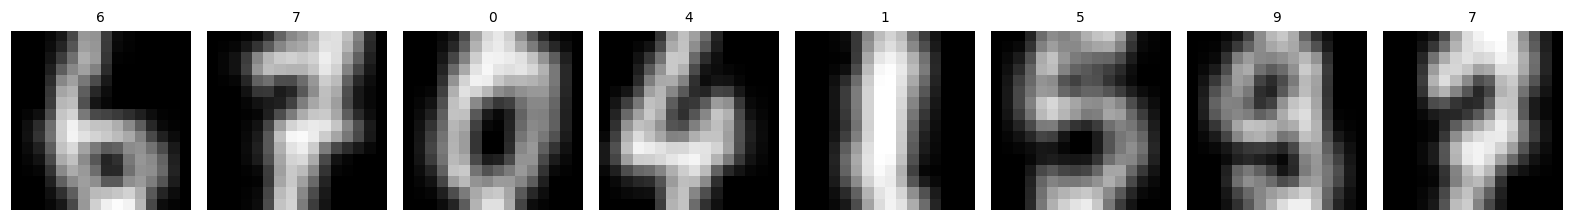

In [5]:
from vision_projects.models import MLP, LeNet

data = digits_data()
train_loader, validation_loader, test_loader = data.loaders()
train_images, train_labels = data.train.tensors
print(
    {
        "train": len(data.train),
        "validation": len(data.validation),
        "test": len(data.test),
    }
)
image_grid(train_images[:8], output / "examples.png", train_labels[:8].tolist())

## Architecture and logits

The MLP flattens the image. LeNet preserves local neighborhoods through convolution and pooling. Both return ten logits, so cross-entropy receives raw scores. Its per-image loss is $-z_y + \log\sum_c e^{z_c}$.

In [7]:
print(inspect.getsource(LeNet))
models = {"mlp": MLP(), "lenet": LeNet()}
for name, candidate in models.items():
    logits = candidate(train_images[:4])
    print(
        name,
        logits.shape,
        sum(parameter.numel() for parameter in candidate.parameters()),
    )
    assert logits.shape == (4, 10)

class LeNet(nn.Module):
    def __init__(self, channels=1, classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(channels, 12, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(12, 24, 3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 4)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(24 * 4 * 4, 64), nn.ReLU(), nn.Linear(64, classes)
        )

    def forward(self, images):
        return self.classifier(self.features(images))

mlp torch.Size([4, 10]) 41802
lenet torch.Size([4, 10]) 28026


## Training comparison

Each run is reseeded before constructing the model, and its DataLoader is rebuilt to keep minibatch order comparable. Validation loss selects the checkpoint; test labels are not used for scheduling or architecture decisions.

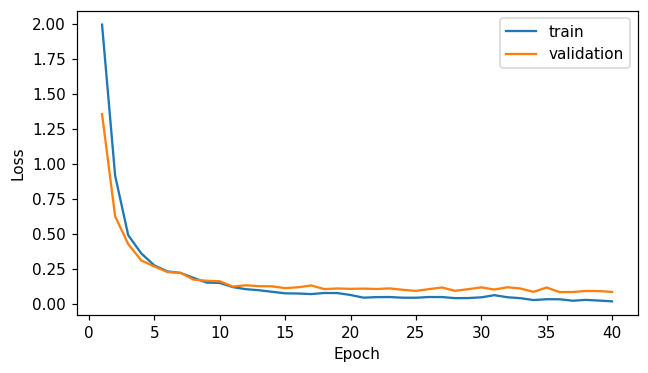

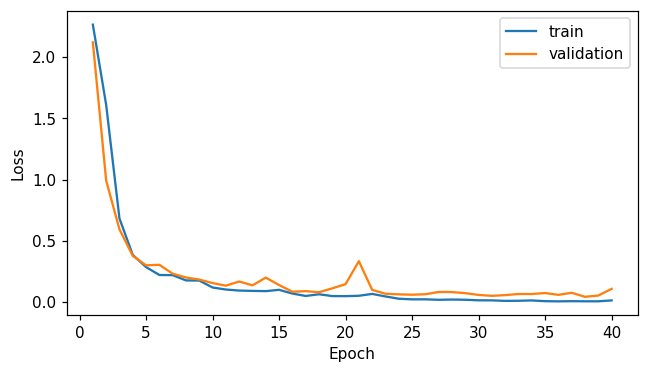

   model  parameters  accuracy  macro_f1       nll
0    mlp       41802  0.963889  0.964169  0.084507
1  lenet       28026  0.977778  0.977984  0.044613
Selected on validation NLL: lenet


In [9]:
rows, trained = [], {}
for name, constructor in [("mlp", MLP), ("lenet", LeNet)]:
    seed_everything()
    candidate = constructor()
    train_loader, validation_loader, test_loader = data.loaders()
    history = Trainer(candidate, nn.CrossEntropyLoss(), TrainConfig(epochs=EPOCHS)).fit(
        train_loader, validation_loader
    )
    plot_history(history, output / f"{name}_loss.png")
    validation_logits, validation_targets = predict(candidate, validation_loader)
    rows.append(
        {
            "model": name,
            "parameters": sum(p.numel() for p in candidate.parameters()),
            **classification_scores(validation_logits, validation_targets),
        }
    )
    trained[name] = candidate
print(pd.DataFrame(rows))
selected = min(rows, key=lambda row: row["nll"])["model"]
model = trained[selected]
print("Selected on validation NLL:", selected)

## Held-out errors

The test set is evaluated after validation has selected weights. The confusion matrix keeps the true class on the vertical axis. Mistakes with high confidence deserve inspection because cross-entropy and accuracy respond differently to them.

{'accuracy': 0.975, 'macro_f1': 0.9747890386926619, 'nll': 0.10337983119860333}
              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.97      1.00      0.99        37
           2       0.97      1.00      0.99        35
           3       1.00      0.95      0.97        37
           4       0.95      1.00      0.97        36
           5       0.94      0.94      0.94        36
           6       1.00      0.97      0.99        36
           7       1.00      1.00      1.00        36
           8       0.94      0.91      0.93        35
           9       0.97      1.00      0.99        36

    accuracy                           0.97       360
   macro avg       0.98      0.97      0.97       360
weighted avg       0.98      0.97      0.97       360



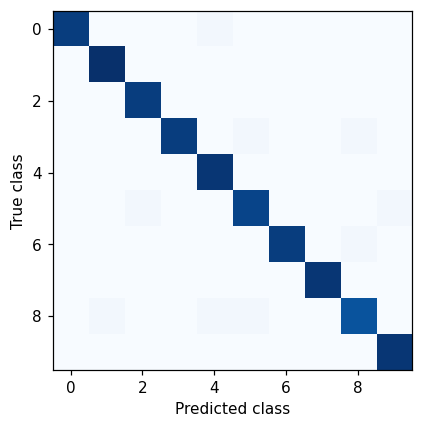

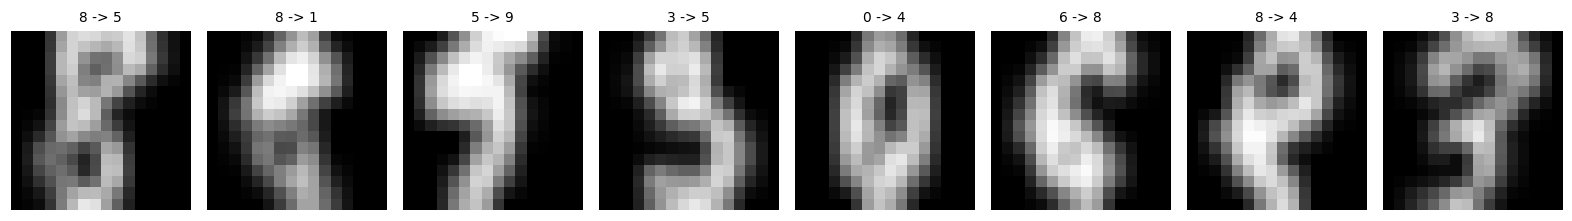

In [11]:
logits, targets = predict(model, test_loader)
scores = classification_scores(logits, targets)
print(scores)
print(classification_report(targets, logits.argmax(-1), zero_division=0))
fig, axis = plt.subplots(figsize=(5, 4))
matrix = confusion_matrix(targets, logits.argmax(-1))
axis.imshow(matrix, cmap="Blues")
axis.set(xlabel="Predicted class", ylabel="True class")
fig.tight_layout()
fig.savefig(output / "confusion.png", dpi=140)
plt.show()
mistakes = torch.where(logits.argmax(-1) != targets)[0]
if len(mistakes):
    mistake_ids = mistakes[:8]
    image_grid(
        data.test.tensors[0][mistake_ids],
        output / "errors.png",
        [f"{int(targets[i])} -> {int(logits[i].argmax())}" for i in mistake_ids],
    )

## Checkpoint round trip

A state dictionary stores learned tensors without pickling the entire model class. The restored model must produce the same logits in evaluation mode. This check protects against changes to inference behavior during code cleanup.

In [13]:
checkpoint = root / "results" / "digit_classifier.pt"
torch.save(model.state_dict(), checkpoint)
restored = LeNet() if selected == "lenet" else MLP()
restored.load_state_dict(torch.load(checkpoint, weights_only=True))
restored.eval()
with torch.inference_mode():
    assert torch.equal(model(train_images[:8]), restored(train_images[:8]))
results = {"validation_comparison": rows, "selected_model": selected, "test": scores}

## Reading the result

Parameter count describes capacity and storage, while the test scores measure this task. The images are small and nearly aligned, so the outcome should not be generalized to large natural-image benchmarks.

Recorded run: In the recorded 40-epoch run, validation NLL selected LeNet. Its held-out test accuracy was 97.5%. The model used 28,026 parameters, compared with 41,802 for the MLP. This result belongs to the small digit dataset and the recorded seed.

In [15]:
result_path = root / "results" / "04_mlp_and_lenet.json"
result_path.write_text(json.dumps(results, indent=2, allow_nan=False) + "\n")
print(result_path.relative_to(root))

results/04_mlp_and_lenet.json


## Next experiment

Add a linear softmax classifier and repeat all three runs over five seeds. Report mean accuracy and its variability using the same held-out identities.

## Sources

UniPd Computer Vision and Cognitive Systems: uploaded filtering, SIFT, BoW, MLP and CNN notebooks. [Practical DL, HSE, YSDA and Skoltech](https://github.com/yandexdataschool/Practical_DL/tree/fall25).

The implementations here were written for this project. Course notebooks and their saved weights are reference material; they are not redistributed.